In [ ]:
#### FITTING THE MODELS WITHOUT BINNING AT ALL ####
# Every test so far computes a weighted median per Teff bin and fits four models to
# those bin values. That makes the answer depend on where the bin edges fall, which is
# the referee's concern, and it leaves only 8 to 37 points to fit -- few enough that
# AICc's small-sample term, 2k(k+1)/(n-k-1), charges the four-parameter model 9.3 in
# chi2 at eight bins but only 2.5 at thirty-seven. That fee is the same size as the
# effect being measured, so which model "wins" partly reflects how finely we binned.
#
# Quantile regression removes both problems. A weighted median is the value m that
# minimises sum(w * |R - m|), so fitting a curve through the median is just minimising
# sum(w * |R - f(Teff)|) over the curve's parameters -- the same estimator, with the
# bins taken out. Every planet enters individually, so there are no edges to place and
# n is fixed at 673 rather than chosen. At n=673 the AICc correction for k=4 is 0.06,
# which is the point: the model comparison stops depending on the binning.
#
# Two things to keep in mind about what this can and cannot settle. The loss is the
# check function at tau=0.5, so this tracks the median exactly as before, but turning
# it into an AICc needs a working likelihood (the asymmetric Laplace), and the radius
# distribution is not really Laplace. Differences in AICc here are therefore on a
# working scale and can be optimistic. That is precisely what the simulation in the
# later cells is for: it measures how often this procedure picks the right model when
# the truth is known, so the numbers printed below can be read with a calibration
# attached rather than taken at face value.

import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

base = '.'
n_bootstrap = 1000


def load_completeness(directory):
    # One master heatmap CSV per Teff slice, stacked with the slice recorded per row
    completeness = pd.DataFrame()
    for f in sorted(glob.glob(os.path.join(directory, 'master_heatmap*.csv'))):
        match = re.search(r'(\d{4})_(\d{4})_K', os.path.basename(f))
        slice_df = pd.read_csv(f)
        slice_df['teff_bin'] = f"{match.group(1)}_{match.group(2)}"
        completeness = pd.concat([completeness, slice_df], ignore_index=True)
    return completeness


def log_edges(centers):
    centers = np.array(sorted(centers))
    logs = np.log10(centers)
    edges = [10 ** (logs[0] - (logs[1] - logs[0]) / 2)]
    for i in range(len(logs) - 1):
        edges.append(10 ** ((logs[i] + logs[i + 1]) / 2))
    edges.append(10 ** (logs[-1] + (logs[-1] - logs[-2]) / 2))
    return np.array(edges)


def cell_index(values, edges):
    inside = (values >= edges[0]) & (values < edges[-1])
    return np.where(inside, np.searchsorted(edges, values, side='right') - 1, np.nan)


completeness = load_completeness(base)
floored = completeness['detection_rate'] == 0
completeness.loc[floored, 'detection_rate'] = 1 / completeness.loc[floored, 'trials']
radius_edges = log_edges(completeness['radius_bin_center'].unique())
period_edges = log_edges(completeness['period_bin_center'].unique())
completeness['radius_cell'] = cell_index(completeness['radius_bin_center'].values, radius_edges)
completeness['period_cell'] = cell_index(completeness['period_bin_center'].values, period_edges)

planets = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv').dropna(subset=['st_teff', 'pl_rade'])
planets = planets[(planets['pl_rade'] > 1.8) & (planets['pl_rade'] < 4.0)]
planets = planets[(planets['pl_orbper'] > 0.6028) & (planets['pl_orbper'] < 25.1)]
planets = planets[planets['st_tmag'] < 13]
if 'tfopwg_disp' in planets.columns:
    planets = planets[planets['tfopwg_disp'] != 'FP']
planets = planets[['toi', 'st_teff', 'pl_rade', 'pl_orbper']].copy()

teff_bins = []
for teff_value in planets['st_teff']:
    found = np.nan
    for teff_min in range(3000, 7000, 500):
        if teff_min <= teff_value < teff_min + 500:
            found = f"{teff_min}_{teff_min + 500}"
    teff_bins.append(found)
planets['teff_bin'] = teff_bins
planets['radius_cell'] = cell_index(planets['pl_rade'].values, radius_edges)
planets['period_cell'] = cell_index(planets['pl_orbper'].values, period_edges)
planets = planets.merge(
    completeness[['teff_bin', 'radius_cell', 'period_cell', 'detection_rate', 'transit_prob']],
    on=['teff_bin', 'radius_cell', 'period_cell'], how='left')
planets['weight'] = (1 / planets['detection_rate'] * 1 / planets['transit_prob']).fillna(1)

teff = planets['st_teff'].values.astype(float)
radius = planets['pl_rade'].values.astype(float)
# Scaled so the weights average to one. Only their relative size matters to the fit,
# and this keeps the effective sample size equal to the number of planets actually
# observed rather than to the sum of the corrections, which would overstate the
# evidence by treating every represented planet as an independent measurement.
weights = planets['weight'].values.astype(float)
weights = weights / weights.mean()

x_min, x_max = teff.min(), teff.max()
n_planets = len(teff)
print(f"{n_planets} planets, Teff {x_min:.0f}-{x_max:.0f} K, "
      f"{int(planets['detection_rate'].notna().sum())} with a completeness cell")
print(f"Weights scaled to mean 1, range {weights.min():.3f}-{weights.max():.1f}")


def plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)


def slope(x, y0, s):
    return y0 + s * (np.asarray(x, dtype=float) - x_min)


def plateau_M(x, c, x1, s1):
    # Rises with slope s1 below x1, flat at c above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c)


def symmetric(x, c, x1, x2, s):
    # Rise, then flat between x1 and x2, then rise again with the same slope
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


models = {
    'Plateau': {'func': plateau, 'k': 1},
    'Slope': {'func': slope, 'k': 2},
    'Plateau+M': {'func': plateau_M, 'k': 3},
    'Symmetric': {'func': symmetric, 'k': 4},
}

model_labels = {
    'Plateau': 'Plateau',
    'Slope': 'Slope',
    'Plateau+M': 'Plateau with one sloping section',
    'Symmetric': 'Plateau with two sloping sections',
}


def check_loss(func, params, teff, radius, weights):
    # The tau=0.5 check function, whose minimiser is the weighted median
    return np.sum(weights * 0.5 * np.abs(radius - func(teff, *params)))


def starting_guesses(name, teff, radius):
    span = x_max - x_min
    level = np.median(radius)
    cool, hot = teff < np.median(teff), teff >= np.median(teff)
    gradient = (np.median(radius[hot]) - np.median(radius[cool])) / span
    if name == 'Plateau':
        return [[level]]
    if name == 'Slope':
        return [[level, gradient]]
    if name == 'Plateau+M':
        return [[level, x_min + f * span, gradient] for f in (0.2, 0.35, 0.5, 0.65, 0.8)]
    return [[level, x_min + a * span, x_min + b * span, gradient]
            for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55), (0.45, 0.85), (0.35, 0.6))]


def fit_model(name, teff, radius, weights):
    # The check loss is piecewise linear, so a gradient-free search is used, started
    # from several breakpoints because the surface is multi-modal in a breakpoint
    func = models[name]['func']
    best_loss, best_params = np.inf, None
    fallback_loss, fallback_params = np.inf, None
    for guess in starting_guesses(name, teff, radius):
        result = minimize(lambda p: check_loss(func, p, teff, radius, weights), guess,
                          method='Powell', options={'maxiter': 20000, 'xtol': 1e-4, 'ftol': 1e-6})
        params = np.array(result.x, dtype=float)
        if name in ('Plateau+M', 'Symmetric'):
            params[1] = np.clip(params[1], x_min, x_max)
            if name == 'Symmetric':
                params[2] = np.clip(params[2], x_min, x_max)
                if params[1] > params[2]:
                    # Crossed breakpoints are meaningless, but a run where every start
                    # crosses must still return something finite or the simulation below
                    # silently loses that sample. Keep the ordered version as a fallback.
                    ordered = params.copy()
                    ordered[1], ordered[2] = params[2], params[1]
                    ordered_loss = check_loss(func, ordered, teff, radius, weights)
                    if ordered_loss < fallback_loss:
                        fallback_loss, fallback_params = ordered_loss, ordered
                    continue
        loss = check_loss(func, params, teff, radius, weights)
        if not np.isfinite(loss):
            continue
        if loss < best_loss:
            best_loss, best_params = loss, params
    if best_params is None:
        return fallback_loss, fallback_params
    return best_loss, best_params


def fit_ladder(teff, radius, weights):
    # AICc from the asymmetric Laplace likelihood, whose MLE scale is the mean check
    # loss. Only differences between models matter, and every model shares the same n.
    n = len(teff)
    ladder = {}
    for name in models:
        loss, params = fit_model(name, teff, radius, weights)
        k = models[name]['k']
        sigma = loss / n
        log_likelihood = n * np.log(0.25) - n * np.log(sigma) - n
        aic = -2 * log_likelihood + 2 * k
        ladder[name] = {'k': k, 'loss': loss, 'params': params,
                        'AICc': aic + 2 * k * (k + 1) / (n - k - 1)}
    return ladder


ladder = fit_ladder(teff, radius, weights)
best_name = min(ladder, key=lambda name: ladder[name]['AICc'])
best_aicc = ladder[best_name]['AICc']

print(f"\nUnbinned quantile regression, all {n_planets} planets")
print("=" * 70)
print(f"{'Model':<12}{'k':>3}{'check loss':>13}{'AICc':>11}{'dAICc':>9}")
print("-" * 70)
for name, model in ladder.items():
    print(f"{name:<12}{model['k']:>3}{model['loss']:>13.3f}"
          f"{model['AICc']:>11.2f}{model['AICc'] - best_aicc:>9.2f}")
print(f"  Preferred by AICc: {best_name}")
print(f"  Plateau:    c={ladder['Plateau']['params'][0]:.3f}")
print(f"  Slope:      y0={ladder['Slope']['params'][0]:.3f}, "
      f"s={ladder['Slope']['params'][1]*1000:.4f} per 1000 K")
print(f"  Plateau+M:  c={ladder['Plateau+M']['params'][0]:.3f}, "
      f"x1={ladder['Plateau+M']['params'][1]:.0f} K, "
      f"s1={ladder['Plateau+M']['params'][2]*1000:.4f} per 1000 K")
print(f"  Symmetric:  c={ladder['Symmetric']['params'][0]:.3f}, "
      f"x1={ladder['Symmetric']['params'][1]:.0f} K, "
      f"x2={ladder['Symmetric']['params'][2]:.0f} K, "
      f"s={ladder['Symmetric']['params'][3]*1000:.4f} per 1000 K")
print(f"\n  AICc small-sample correction at n={n_planets}, k=4: "
      f"{2*4*5/(n_planets-5):.3f}  (it was 13.33 at eight bins)")

673 planets, Teff 3131-6920 K, 672 with a completeness cell
Weights scaled to mean 1, range 0.026-6.6

Unbinned quantile regression, all 673 planets
Model         k   check loss       AICc    dAICc
----------------------------------------------------------------------
Plateau       1      134.852    1050.18    49.02
Slope         2      132.171    1025.16    24.00
Plateau+M     3      130.648    1011.57    10.41
Symmetric     4      129.446    1001.16     0.00
  Preferred by AICc: Symmetric
  Plateau:    c=2.431
  Slope:      y0=2.208, s=0.1113 per 1000 K
  Plateau+M:  c=2.470, x1=4314 K, s1=0.4439 per 1000 K
  Symmetric:  c=2.462, x1=4227 K, x2=6108 K, s=0.4786 per 1000 K

  AICc small-sample correction at n=673, k=4: 0.060  (it was 13.33 at eight bins)


Bootstrap over 500 resamples of the 673 planets
  Plateau+M  c         = 2.516 [2.449, 2.626]
             x1        = 4680 K [4251, 6745]
             s1        = 0.245 [0.118, 0.504] per 1000 K
  Symmetric  c         = 2.463 [2.431, 2.522]
             x1        = 4285 K [4176, 5136]
             x2        = 6101 K [5810, 6304]
             s         = 0.418 [0.133, 0.541] per 1000 K
  Plateau+M s1: 0.0% of resamples at or below zero
  Symmetric s: 0.4% of resamples at or below zero
  Breakpoint 68% widths: x1 spans 960 K, x2 spans 494 K


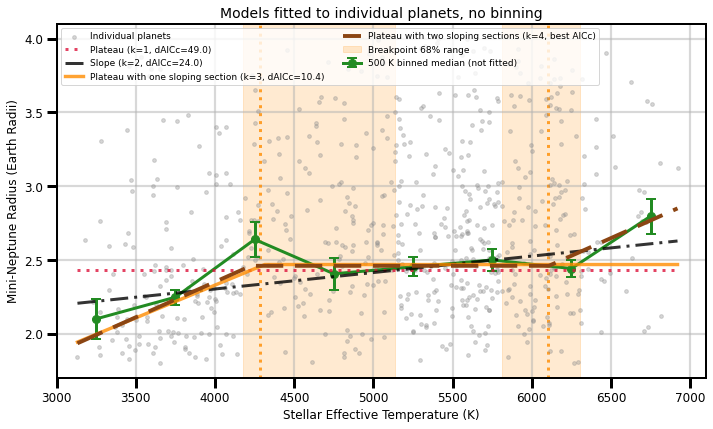

In [ ]:
#### PARAMETER UNCERTAINTIES AND WHAT THE UNBINNED FIT LOOKS LIKE ####
# Resampling planets with replacement and refitting gives the spread on each parameter
# without any bin structure entering. The breakpoints are the interesting ones: if the
# cool-end break is real it should come back in a narrow range, and if the hot-end break
# is not, it should wander across whatever room the fit allows it.
#
# The binned medians are drawn underneath purely as a sanity check that the curve passes
# through the points the earlier notebooks were fitting. They take no part in the fit.

rng = np.random.default_rng(11)
n_bootstrap_params = 500

bootstrap = {'Plateau+M': [], 'Symmetric': []}
for _ in range(n_bootstrap_params):
    pick = rng.integers(0, n_planets, size=n_planets)
    for name in bootstrap:
        loss, params = fit_model(name, teff[pick], radius[pick], weights[pick])
        if params is not None:
            bootstrap[name].append(params)

for name in bootstrap:
    bootstrap[name] = np.array(bootstrap[name])

print(f"Bootstrap over {n_bootstrap_params} resamples of the {n_planets} planets")
print("=" * 72)
one = bootstrap['Plateau+M']
print(f"  Plateau+M  c         = {np.median(one[:, 0]):.3f} "
      f"[{np.percentile(one[:, 0], 16):.3f}, {np.percentile(one[:, 0], 84):.3f}]")
print(f"             x1        = {np.median(one[:, 1]):.0f} K "
      f"[{np.percentile(one[:, 1], 16):.0f}, {np.percentile(one[:, 1], 84):.0f}]")
print(f"             s1        = {np.median(one[:, 2])*1000:.3f} "
      f"[{np.percentile(one[:, 2], 16)*1000:.3f}, {np.percentile(one[:, 2], 84)*1000:.3f}] per 1000 K")
two = bootstrap['Symmetric']
print(f"  Symmetric  c         = {np.median(two[:, 0]):.3f} "
      f"[{np.percentile(two[:, 0], 16):.3f}, {np.percentile(two[:, 0], 84):.3f}]")
print(f"             x1        = {np.median(two[:, 1]):.0f} K "
      f"[{np.percentile(two[:, 1], 16):.0f}, {np.percentile(two[:, 1], 84):.0f}]")
print(f"             x2        = {np.median(two[:, 2]):.0f} K "
      f"[{np.percentile(two[:, 2], 16):.0f}, {np.percentile(two[:, 2], 84):.0f}]")
print(f"             s         = {np.median(two[:, 3])*1000:.3f} "
      f"[{np.percentile(two[:, 3], 16)*1000:.3f}, {np.percentile(two[:, 3], 84)*1000:.3f}] per 1000 K")

# A slope consistent with zero would mean the sloping section is not needed at all
for name, column, what in [('Plateau+M', 2, 's1'), ('Symmetric', 3, 's')]:
    values = bootstrap[name][:, column]
    print(f"  {name} {what}: {100*np.mean(values <= 0):.1f}% of resamples at or below zero")
# How much of the grid the hot-end break explores, as a sign of whether it is pinned
span_x2 = np.percentile(two[:, 2], 84) - np.percentile(two[:, 2], 16)
span_x1 = np.percentile(two[:, 1], 84) - np.percentile(two[:, 1], 16)
print(f"  Breakpoint 68% widths: x1 spans {span_x1:.0f} K, x2 spans {span_x2:.0f} K")


def weighted_median(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if keep.sum() == 0:
        return np.nan
    values, weights = values[keep], weights[keep]
    order = np.argsort(values)
    values, weights = values[order], weights[order]
    return float(values[np.searchsorted(np.cumsum(weights), 0.5 * weights.sum())])


def binned_medians(teff, radius, weights, edges, n_boot=300, seed=11):
    # The estimator the earlier notebooks use, kept here only for the overlay and for
    # the binned arm of the simulation below
    boot_rng = np.random.default_rng(seed)
    centers, medians, errors = [], [], []
    for i in range(len(edges) - 1):
        mask = (teff >= edges[i]) & (teff < edges[i + 1])
        if mask.sum() < 2:
            continue
        draws = []
        for _ in range(n_boot):
            pick = boot_rng.integers(0, int(mask.sum()), size=int(mask.sum()))
            draws.append(weighted_median(radius[mask][pick], weights[mask][pick]))
        error = np.nanstd(draws)
        if not np.isfinite(error) or error <= 1e-12:
            continue
        centers.append((edges[i] + edges[i + 1]) / 2)
        medians.append(weighted_median(radius[mask], weights[mask]))
        errors.append(error)
    return np.array(centers), np.array(medians), np.array(errors)


bins_500 = list(range(3000, 7001, 500))
bin_centers, bin_medians, bin_errors = binned_medians(teff, radius, weights, bins_500)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Individual planet radii as grey transparent dots
ax.scatter(teff, radius, s=14, color='0.55', alpha=0.35, zorder=2, label='Individual planets')
ax.errorbar(bin_centers, bin_medians, yerr=bin_errors, color='forestgreen',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5, capthick=2,
            zorder=4, label='500 K binned median (not fitted)')

model_styles = {
    'Plateau': ('crimson', (0, (1, 2)), 3.0),
    'Slope': ('black', (0, (6, 2, 1, 2)), 3.0),
    'Plateau+M': ('darkorange', '-', 3.4),
    'Symmetric': ('saddlebrown', (0, (7, 3)), 2.4),
}
x_line = np.linspace(x_min, x_max, 600)
for name, (color, linestyle, linewidth) in model_styles.items():
    model = ladder[name]
    is_best = name == best_name
    if is_best:
        label = f"{model_labels[name]} (k={model['k']}, best AICc)"
    else:
        label = f"{model_labels[name]} (k={model['k']}, dAICc={model['AICc'] - best_aicc:.1f})"
    ax.plot(x_line, models[name]['func'](x_line, *model['params']), color=color, linestyle=linestyle,
            linewidth=linewidth + 1.5 if is_best else linewidth,
            alpha=1.0 if is_best else 0.8, zorder=5, label=label)

for value, name in ((np.median(two[:, 1]), 'Breakpoint 1'), (np.median(two[:, 2]), 'Breakpoint 2')):
    ax.axvline(value, color='darkorange', linestyle=':', linewidth=3, alpha=0.8, zorder=1)
ax.axvspan(np.percentile(two[:, 1], 16), np.percentile(two[:, 1], 84),
           color='darkorange', alpha=0.18, zorder=0, label='Breakpoint 68% range')
ax.axvspan(np.percentile(two[:, 2], 16), np.percentile(two[:, 2], 84),
           color='darkorange', alpha=0.18, zorder=0)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Mini-Neptune Radius (Earth Radii)', size=12)
ax.set_xlim(3000, 7100)
ax.set_ylim(1.7, 4.1)
ax.set_title('Models fitted to individual planets, no binning', size=14)
ax.legend(loc='upper left', fontsize=9, ncol=2)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_unbinned.png', dpi=300, bbox_inches='tight')

Simulated 400 samples per truth, 673 planets each
truth                      Plateau    Slope   1 section   2 sections
------------------------------------------------------------------------------
one sloping section           1.5%    19.0%       60.5%        19.0%
two sloping sections          0.0%    39.0%       19.8%        41.2%

The quantity the paper leans on is dAICc(two sections - one section).
Observed in the real data: -10.41 (two sloping sections preferred)
------------------------------------------------------------------------------
  truth = one sloping section    median    +1.99, 68% range [-1.52, +2.29]
  truth = two sloping sections   median    +0.18, 68% range [-10.78, +3.17]
  P(dAICc <= observed | truth = one sloping section   ) = 0.062
  P(dAICc <= observed | truth = two sloping sections  ) = 0.168

  False positive rate (picks two when truth is one): 19.0%
  Power               (picks two when truth is two): 41.2%


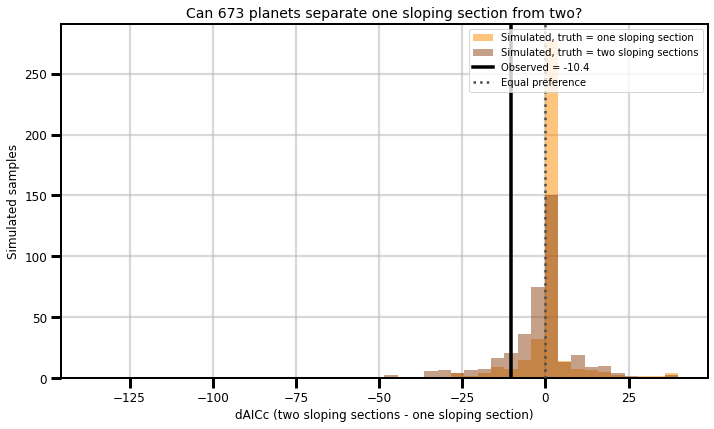

In [ ]:
#### CAN THIS DATASET TELL ONE SLOPING SECTION FROM TWO? ####
# Every test so far has reported which model won without ever asking whether the data
# are capable of answering. This asks directly: build synthetic samples from a known
# truth, push them through the identical procedure, and count how often it recovers the
# model it was given.
#
# Each synthetic sample keeps the real Teff values and the real weights, so the sampling
# of stars and the corrections are exactly those of the actual survey. Only the radii
# are replaced: radius = truth(Teff) + residual, with residuals resampled from the real
# fit residuals so the scatter keeps its real shape and width rather than being assumed
# Gaussian.
#
# Two truths are run. Under "one sloping section" the procedure should rarely prefer two
# -- how often it does is the false-positive rate, and if that is high then a win for
# two sloping sections in the real data means very little. Under "two sloping sections"
# the fraction of times it recovers two is the power, and if that is low then a win for
# one sloping section means very little either. A procedure can easily fail both ways at
# once, which is the outcome worth knowing about before any of this goes in a paper.

n_simulations = 400
sim_rng = np.random.default_rng(11)

truths = {
    'one sloping section': ('Plateau+M', ladder['Plateau+M']['params']),
    'two sloping sections': ('Symmetric', ladder['Symmetric']['params']),
}

# Residuals about each truth, resampled to give the synthetic planets their scatter
residual_pool = {}
for label, (name, params) in truths.items():
    residual_pool[label] = radius - models[name]['func'](teff, *params)


def simulate(label):
    name, params = truths[label]
    draw = sim_rng.integers(0, n_planets, size=n_planets)
    return models[name]['func'](teff, *params) + residual_pool[label][draw]


results = {}
for label in truths:
    picked = []
    delta_two_minus_one = []
    for _ in range(n_simulations):
        fake_radius = simulate(label)
        fake = fit_ladder(teff, fake_radius, weights)
        picked.append(min(fake, key=lambda m: fake[m]['AICc']))
        delta_two_minus_one.append(fake['Symmetric']['AICc'] - fake['Plateau+M']['AICc'])
    delta = np.array(delta_two_minus_one)
    dropped = int(np.sum(~np.isfinite(delta)))
    if dropped:
        print(f"  {label}: {dropped} of {n_simulations} samples dropped for a failed fit")
    results[label] = {'picked': picked, 'delta': delta[np.isfinite(delta)]}

print(f"Simulated {n_simulations} samples per truth, {n_planets} planets each")
print("=" * 78)
print(f"{'truth':<24}{'Plateau':>10}{'Slope':>9}{'1 section':>12}{'2 sections':>13}")
print("-" * 78)
for label in truths:
    picked = results[label]['picked']
    counts = {name: picked.count(name) / n_simulations for name in models}
    print(f"{label:<24}{counts['Plateau']:>10.1%}{counts['Slope']:>9.1%}"
          f"{counts['Plateau+M']:>12.1%}{counts['Symmetric']:>13.1%}")

observed_delta = ladder['Symmetric']['AICc'] - ladder['Plateau+M']['AICc']
print(f"\nThe quantity the paper leans on is dAICc(two sections - one section).")
print(f"Observed in the real data: {observed_delta:+.2f} "
      f"({'two' if observed_delta < 0 else 'one'} sloping section{'s' if observed_delta < 0 else ''} preferred)")
print("-" * 78)
for label in truths:
    delta = results[label]['delta']
    print(f"  truth = {label:<22} median {np.median(delta):>+8.2f}, "
          f"68% range [{np.percentile(delta, 16):+.2f}, {np.percentile(delta, 84):+.2f}]")

# Where the observed value sits inside each simulated distribution is the calibration:
# if it is unremarkable under the one-section truth, it is not evidence against it
for label in truths:
    delta = results[label]['delta']
    print(f"  P(dAICc <= observed | truth = {label:<22}) = "
          f"{np.mean(delta <= observed_delta):.3f}")

false_positive = results['one sloping section']['picked'].count('Symmetric') / n_simulations
power = results['two sloping sections']['picked'].count('Symmetric') / n_simulations
print(f"\n  False positive rate (picks two when truth is one): {false_positive:.1%}")
print(f"  Power               (picks two when truth is two): {power:.1%}")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

edges = np.linspace(min(results[l]['delta'].min() for l in truths),
                    max(results[l]['delta'].max() for l in truths), 45)
for label, color in (('one sloping section', 'darkorange'), ('two sloping sections', 'saddlebrown')):
    ax.hist(results[label]['delta'], bins=edges, alpha=0.5, color=color,
            label=f'Simulated, truth = {label}')
ax.axvline(observed_delta, color='black', linewidth=3.5, zorder=5,
           label=f'Observed = {observed_delta:+.1f}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=4,
           label='Equal preference')

ax.set_xlabel('dAICc (two sloping sections - one sloping section)', size=12)
ax.set_ylabel('Simulated samples', size=12)
ax.set_title(f'Can {n_planets} planets separate one sloping section from two?', size=14)
ax.legend(loc='upper right', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_power_unbinned.png', dpi=300, bbox_inches='tight')

Simulated 200 samples per truth, scored the 500 K binned way
truth                      Plateau    Slope   1 section   2 sections
------------------------------------------------------------------------------
one sloping section          26.5%    43.5%       30.0%         0.0%
two sloping sections         15.0%    60.0%       23.0%         2.0%

  False positive rate (picks two when truth is one): 0.0%
  Power               (picks two when truth is two): 2.0%

How often is the flat plateau correctly rejected?
  truth = one sloping section    flat picked 26.5% of the time
  truth = two sloping sections   flat picked 15.0% of the time

Unbinned against binned, same synthetic samples
------------------------------------------------------------
                            false positive     power
unbinned (n=673)                    19.0%     41.2%
500 K binned (n=8)                   0.0%      2.0%


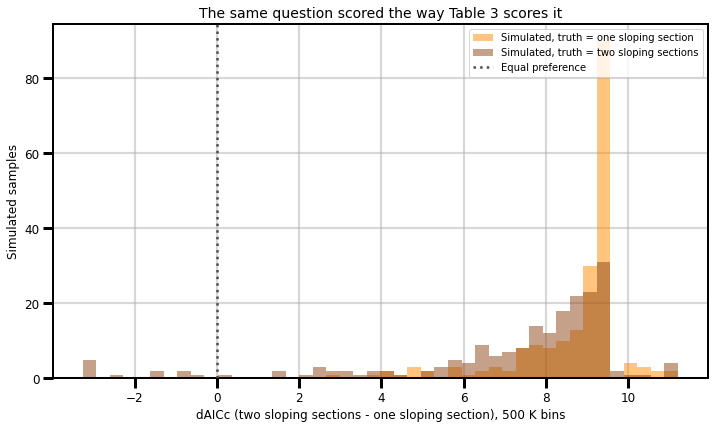

In [ ]:
#### THE SAME QUESTION ASKED OF THE BINNED PROCEDURE IN THE PAPER ####
# The cell above calibrates the unbinned fit. Table 3 does not use the unbinned fit, so
# this repeats the exercise on the procedure the paper actually reports: 500 K bins,
# completeness-corrected weighted median per bin, bootstrap error bars, four models
# compared by AICc on eight points. The synthetic samples are generated exactly as
# before, so the only thing that changes between this cell and the last is the estimator.
#
# This is the number to quote if a referee asks what a dAICc of one or two in Table 3
# actually buys.

from scipy.optimize import curve_fit

n_simulations_binned = 200
binned_rng = np.random.default_rng(11)


def fit_ladder_binned(centers, medians, errors):
    # The curve_fit ladder used by the earlier notebooks, on bin values
    n_bins = len(medians)
    span = centers.max() - centers.min()
    level = np.median(medians)
    gradient = (medians[-1] - medians[0]) / span

    def slope_here(x, y0, s):
        return y0 + s * (np.asarray(x, dtype=float) - centers.min())

    setup = {
        'Plateau': (plateau, 1, [[level]], (-np.inf, np.inf)),
        'Slope': (slope_here, 2, [[medians[0], gradient]], (-np.inf, np.inf)),
        'Plateau+M': (plateau_M, 3,
                      [[level, centers.min() + f * span, gradient] for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
                      ([-np.inf, centers.min(), -np.inf], [np.inf, centers.max(), np.inf])),
        'Symmetric': (symmetric, 4,
                      [[level, centers.min() + a * span, centers.min() + b * span, gradient]
                       for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55), (0.45, 0.85), (0.35, 0.6))],
                      ([-np.inf, centers.min(), centers.min(), -np.inf],
                       [np.inf, centers.max(), centers.max(), np.inf])),
    }
    out = {}
    for name, (func, k, guess_list, bounds) in setup.items():
        best_chi2, best_params = np.inf, None
        for guess in guess_list:
            try:
                params, _ = curve_fit(func, centers, medians, p0=guess, sigma=errors,
                                      absolute_sigma=True, bounds=bounds, maxfev=40000)
            except Exception:
                continue
            if name == 'Symmetric' and params[1] > params[2]:
                continue
            chi2 = np.sum(((medians - func(centers, *params)) / errors) ** 2)
            if chi2 < best_chi2:
                best_chi2, best_params = chi2, params
        if best_params is None:
            return None
        out[name] = {'k': k, 'AICc': best_chi2 + 2 * k + 2 * k * (k + 1) / (n_bins - k - 1)}
    return out


results_binned = {}
for label in truths:
    picked = []
    delta_two_minus_one = []
    for i in range(n_simulations_binned):
        fake_radius = simulate(label)
        centers, medians, errors = binned_medians(teff, fake_radius, weights, bins_500,
                                                  n_boot=200, seed=int(binned_rng.integers(1e6)))
        if len(medians) < 6:
            continue
        fake = fit_ladder_binned(centers, medians, errors)
        if fake is None:
            continue
        picked.append(min(fake, key=lambda m: fake[m]['AICc']))
        delta_two_minus_one.append(fake['Symmetric']['AICc'] - fake['Plateau+M']['AICc'])
    delta = np.array(delta_two_minus_one)
    results_binned[label] = {'picked': picked, 'delta': delta[np.isfinite(delta)]}

print(f"Simulated {n_simulations_binned} samples per truth, scored the 500 K binned way")
print("=" * 78)
print(f"{'truth':<24}{'Plateau':>10}{'Slope':>9}{'1 section':>12}{'2 sections':>13}")
print("-" * 78)
for label in truths:
    picked = results_binned[label]['picked']
    total = len(picked)
    counts = {name: picked.count(name) / total for name in models}
    print(f"{label:<24}{counts['Plateau']:>10.1%}{counts['Slope']:>9.1%}"
          f"{counts['Plateau+M']:>12.1%}{counts['Symmetric']:>13.1%}")

false_positive_binned = (results_binned['one sloping section']['picked'].count('Symmetric')
                         / len(results_binned['one sloping section']['picked']))
power_binned = (results_binned['two sloping sections']['picked'].count('Symmetric')
                / len(results_binned['two sloping sections']['picked']))
print(f"\n  False positive rate (picks two when truth is one): {false_positive_binned:.1%}")
print(f"  Power               (picks two when truth is two): {power_binned:.1%}")

print("\nHow often is the flat plateau correctly rejected?")
for label in truths:
    picked = results_binned[label]['picked']
    print(f"  truth = {label:<22} flat picked {picked.count('Plateau')/len(picked):.1%} of the time")

print("\nUnbinned against binned, same synthetic samples")
print("-" * 60)
print(f"{'':<26}{'false positive':>16}{'power':>10}")
print(f"{'unbinned (n=673)':<26}{false_positive:>15.1%}{power:>10.1%}")
print(f"{'500 K binned (n=8)':<26}{false_positive_binned:>15.1%}{power_binned:>10.1%}")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

all_delta = np.concatenate([results_binned[l]['delta'] for l in truths])
edges = np.linspace(np.percentile(all_delta, 1), np.percentile(all_delta, 99), 45)
for label, color in (('one sloping section', 'darkorange'), ('two sloping sections', 'saddlebrown')):
    ax.hist(np.clip(results_binned[label]['delta'], edges[0], edges[-1]), bins=edges,
            alpha=0.5, color=color, label=f'Simulated, truth = {label}')
ax.axvline(0, color='0.3', linestyle=':', linewidth=2.5, zorder=4, label='Equal preference')

ax.set_xlabel('dAICc (two sloping sections - one sloping section), 500 K bins', size=12)
ax.set_ylabel('Simulated samples', size=12)
ax.set_title('The same question scored the way Table 3 scores it', size=14)
ax.legend(loc='upper right', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_power_binned.png', dpi=300, bbox_inches='tight')